# Demo: Guided Nowcasting with `NowcastSSM`

This notebook demonstrates the current `NowcastSSM` API on synthetic Lorenz96 data.

- Historical training data are fully observed.
- The model learns conditional completion through internal pseudo guidance masking during training.
- At inference time, we hide coordinate `0` and compare its future trajectory under unguided rollout versus a random reveal of `K` future coordinates.


In [1]:
from pathlib import Path
import os, sys

repo_root = Path.cwd()
if repo_root.name == 'demo':
    repo_root = repo_root.parent
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
torch.set_float32_matmul_precision('high')
from torch.utils.data import DataLoader

from demo.eval import (
    forecast_from_trajectory,
    reconstruct_context_plus_one_from_trajectory,
    reconstruct_context_same_grid_from_trajectory,
)
from demo.lorenz96 import SimLorenz
from src.data.dataset_ssm import TSDataset
from src.models import NowcastSSM, NowcastModelConfig, NowcastOptConfig
from src.utils.trainer import configure_trainer

%matplotlib inline


In [3]:
SEED = 123
GPU_ID = 0
NUM_WORKERS = 4
BATCH_SIZE = 128

LATENT_DIM = 5
OBS_DIM = 30
DELTA_T = 0.05
FORCE = 2.8
OBS_NOISE_SCALE = 0.15
TOTAL_STEPS = 50000
TRAIN_STEPS = 40000
VAL_STEPS = 5000
FORECAST_HORIZON = 20
CONTEXT_LEN = 80
TRAIN_STRIDE = 5
VAL_STRIDE = 10

OUTPUT_DIR = Path('output/discrete_nowcast')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

## 1. Generate synthetic data

We use Lorenz96 latent dynamics and an explicit linear emission matrix. The observation series is fully observed; there is no external observation missingness during training.

In [5]:
rng = np.random.default_rng(SEED)

emission_matrix = rng.normal(size=(OBS_DIM, LATENT_DIM)).astype(np.float64)
emission_matrix /= np.linalg.norm(emission_matrix, axis=1, keepdims=True).clip(min=1.0e-8)

simulator = SimLorenz(
    latent_dim=LATENT_DIM,
    obs_dim=OBS_DIM,
    force=FORCE,
    delta_t=DELTA_T,
    burn_in=1000,
    obs_noise_scale=OBS_NOISE_SCALE,
    emission_matrix=emission_matrix,
    seed=SEED,
)

z_raw, tps = simulator.sim_latent_process(n_steps=TOTAL_STEPS, seed=SEED)
x_raw = simulator.sim_observation_process(z_raw, seed=SEED, emission_matrix=emission_matrix)

if not np.isfinite(z_raw).all():
    raise ValueError('Lorenz96 latent simulation produced non-finite values. Adjust FORCE, DELTA_T, or noise settings.')
if not np.isfinite(x_raw).all():
    raise ValueError('Observation simulation produced non-finite values. Check latent stability and emission settings.')

obs_df = pd.DataFrame(x_raw, index=tps)
latent_df = pd.DataFrame(z_raw, index=tps)

T_OBS = TRAIN_STEPS + VAL_STEPS
assert T_OBS + FORECAST_HORIZON <= len(obs_df)

train_df = obs_df.iloc[:TRAIN_STEPS]
val_df = obs_df.iloc[TRAIN_STEPS:T_OBS]
future_df = obs_df.iloc[T_OBS:T_OBS + FORECAST_HORIZON]

print('observation shape:', obs_df.shape)
print('latent shape:', latent_df.shape)
print('train / val / future:', train_df.shape, val_df.shape, future_df.shape)

observation shape: (50000, 30)
latent shape: (50000, 5)
train / val / future: (40000, 30) (5000, 30) (20, 30)


## 2. Train `NowcastSSM`

The small validation split exists only because the current `configure_trainer(...)` monitors `val_loss`. The nowcasting behavior itself is learned from internal pseudo guidance masking during training.

In [6]:
train_ds = TSDataset(
    data=train_df,
    context_len=CONTEXT_LEN,
    pred_len=0,
    stride=TRAIN_STRIDE,
    relative_timestamps=True,
)
val_ds = TSDataset(
    data=val_df,
    context_len=CONTEXT_LEN,
    pred_len=0,
    stride=VAL_STRIDE,
    relative_timestamps=True,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
)

sample_batch = next(iter(train_loader))
print('sample batch keys:', sample_batch.keys())
print('x_traj shape:', tuple(sample_batch['x_traj'].shape))
print('x_mask unique values:', torch.unique(sample_batch['x_mask']))

sample batch keys: dict_keys(['x_traj', 'x_mask', 'x_tps'])
x_traj shape: (128, 80, 30)
x_mask unique values: tensor([1.])


In [7]:
model_cfg = NowcastModelConfig(
    dim_obs=OBS_DIM,
    dim_latent=LATENT_DIM,
    enc_proj_dim=64,
    enc_rnn_hidden_dim=64,
    enc_rnn_num_layers=1,
    mask_processor_kernel_size=3,
    ar_proj_hidden_dim=128,
    ar_mean_net_hidden_dim=64,
    ar_sigma_net_hidden_dim=64,
    dec_hidden_dim=[128, 64],
    x_sigma2=0.05,
    z_sigma_type='diag',
    dropout=0.05,
)

opt_cfg = NowcastOptConfig(
        n_epochs=50,
        batch_size=BATCH_SIZE,
        lr=5e-4,
        scheduler_type='MultiStepLR',
        milestones=[20, 40],
        gamma=0.5,
        weight_decay=1e-6,
        loss_type='NLL',
        loss_reduction='mean',
        mc_samples=0,
        beta_max=1.0,
        warmup_epochs=8,
        pseudo_guidance_mask_prob=(0.10, 0.30),
        unguided_sample_ratio=0.10,
        allow_all_zero_target_mask=False,
    )

masked_module = NowcastSSM(model_cfg, opt_cfg)
trainer = configure_trainer(
    opt_cfg,
    gpu_id=GPU_ID if torch.cuda.is_available() else None,
    output_dir=OUTPUT_DIR,
    verbosity=10,
)
trainer.fit(masked_module, train_dataloaders=train_loader, val_dataloaders=val_loader)
masked_module.eval()

NowcastModelConfig(dim_obs=30, dim_latent=5, enc_proj_dim=64, enc_rnn_hidden_dim=64, enc_rnn_num_layers=1, mask_processor_kernel_size=3, ar_proj_hidden_dim=128, ar_mean_net_hidden_dim=64, ar_sigma_net_hidden_dim=64, dec_hidden_dim=[128, 64], x_sigma2=0.05, z_sigma_type='diag', dropout=0.05)
----------------
NowcastOptConfig(n_epochs=50, batch_size=128, lr=0.0005, scheduler_type='MultiStepLR', weight_decay=1e-06, check_val_every_n_epoch=1, gradient_clip_val=0.0, limit_val_batches=100, gradient_accumulation_steps=1, early_stopping=None, factor=None, patience=None, step_size=None, gamma=0.5, milestones=[20, 40], loss_type='NLL', loss_reduction='mean', train_strategy='reconstruct', mc_samples=0, beta_max=1.0, warmup_epochs=8, pseudo_guidance_mask_prob=(0.1, 0.3), unguided_sample_ratio=0.1, allow_all_zero_target_mask=False)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]

  | Name  | Type               | Params | Mode 
-----------------------------------------------------
0 | elbo  | ELBO               | 0      | train
1 | model | LatentNowcastModel | 249 K  | train
-----------------------------------------------------
249 K     Trainable params
0         Non-trainable params
249 K     Total params
0.998     Total estimated model params size (MB)
73        Modules in train mode
0         Modules in eval mode


EPOCH=001 (timer=4s/epoch); train_loss=23.2026; val_loss=18.2958; lr=5.0E-04
    - train_err=23.16; val_err=18.20; train_kl=0.32; val_kl=0.79; 
EPOCH=010 (timer=3s/epoch); train_loss=-0.6480; val_loss=-1.0838; lr=5.0E-04
    - train_err=-0.66; val_err=-1.09; train_kl=0.02; val_kl=0.01; 
EPOCH=020 (timer=3s/epoch); train_loss=-0.8630; val_loss=-1.1775; lr=2.5E-04
    - train_err=-0.87; val_err=-1.18; train_kl=0.01; val_kl=0.00; 
EPOCH=030 (timer=3s/epoch); train_loss=-0.9146; val_loss=-1.1925; lr=2.5E-04
    - train_err=-0.92; val_err=-1.19; train_kl=0.00; val_kl=0.00; 
EPOCH=040 (timer=3s/epoch); train_loss=-0.9562; val_loss=-1.2075; lr=1.3E-04
    - train_err=-0.96; val_err=-1.21; train_kl=0.00; val_kl=0.00; 


`Trainer.fit` stopped: `max_epochs=50` reached.


EPOCH=050 (timer=3s/epoch); train_loss=-0.9747; val_loss=-1.2151; lr=1.3E-04
    - train_err=-0.98; val_err=-1.22; train_kl=0.00; val_kl=0.00; 


NowcastSSM(
  (elbo): ELBO(
    (loss_obj): GaussianNLLLoss()
  )
  (model): LatentNowcastModel(
    (posterior_encoder): BiRNNEncoder(
      (softplus): Softplus(beta=1.0, threshold=20.0)
      (x_projection): MLP(
        (ffnet): Sequential(
          (0): Linear(in_features=30, out_features=64, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.05, inplace=False)
          (3): Linear(in_features=64, out_features=64, bias=True)
        )
      )
      (mask_1dcnn): Conv1d(30, 128, kernel_size=(3,), stride=(1,), padding=same)
      (mask_projector): Sequential(
        (0): GELU(approximate='none')
        (1): Linear(in_features=128, out_features=64, bias=True)
      )
      (birnn): GRU(65, 64, batch_first=True, bidirectional=True)
      (combiner_forward_mu): Linear(in_features=64, out_features=5, bias=True)
      (combiner_backward_mu): Linear(in_features=64, out_features=5, bias=True)
      (combiner_forward_sigma): Sequential(
        (0): Linear(in_

## 3. Build the guided-generation scenario

Coordinate `0` is always hidden in the future horizon. We randomly reveal `K` other future coordinates and use them as the guidance signal for nowcasting.


In [8]:
TARGET_COORD = 0
GUIDANCE_K = 10


In [9]:
def build_random_guidance_case(
    x_future: np.ndarray,
    dim_obs: int,
    hidden_coord: int,
    k: int,
    rng: random.Random,
):
    candidate_coords = [idx for idx in range(dim_obs) if idx != hidden_coord]
    if len(candidate_coords) < k:
        raise ValueError(f'Only {len(candidate_coords)} revealable coordinates available but GUIDANCE_K={k}.')

    guidance_coords = sorted(rng.sample(candidate_coords, k))
    guidance_mask = np.zeros((x_future.shape[0], dim_obs), dtype=np.float32)
    guidance_mask[:, guidance_coords] = 1.0
    guidance_x = x_future.astype(np.float32) * guidance_mask
    return guidance_x, guidance_mask, guidance_coords


In [10]:
future_x = future_df.to_numpy(dtype=np.float32)
guidance_rng = random.Random(SEED)
guidance_x, guidance_mask, guidance_coords = build_random_guidance_case(
    x_future=future_x,
    dim_obs=OBS_DIM,
    hidden_coord=TARGET_COORD,
    k=GUIDANCE_K,
    rng=guidance_rng,
)

guidance_cases = {
    'random': {
        'guidance_x': guidance_x,
        'guidance_mask': guidance_mask,
        'coords': guidance_coords,
    }
}
print('random guidance coordinates:', guidance_coords)


random guidance coordinates: [2, 3, 4, 9, 13, 14, 18, 25, 28, 29]


## 4. Run causal guided rollout

We first check that the model behaves like the reference discrete demo in the unguided setting: fit the in-sample context and then roll forward over the future horizon. After that, we compare the unguided rollout against a single random-reveal guidance case.


In [11]:
device = masked_module.device

context_start = T_OBS - CONTEXT_LEN
if context_start < 0:
    raise ValueError('CONTEXT_LEN exceeds the available observed history.')

history_x = torch.tensor(obs_df.iloc[context_start:T_OBS].to_numpy(), dtype=torch.float32, device=device)
history_mask = torch.ones_like(history_x)
history_tps = torch.tensor(obs_df.index[context_start:T_OBS].to_numpy(), dtype=torch.float32, device=device)
future_tps = torch.tensor(future_df.index.to_numpy(), dtype=torch.float32, device=device)
context_truth_coord0 = history_x[:, TARGET_COORD].detach().cpu().numpy()
truth_coord0 = future_x[:, TARGET_COORD]

def evaluate_rollouts(lightning_module, guidance_cases=None):
    network = lightning_module.model
    x_fit_same_grid, t_fit_same_grid = reconstruct_context_same_grid_from_trajectory(
        network=network,
        x=history_x,
        mask=history_mask,
        time_steps=history_tps,
    )
    x_fit_plus_one, t_fit_plus_one = reconstruct_context_plus_one_from_trajectory(
        network=network,
        x=history_x,
        mask=history_mask,
        time_steps=history_tps,
    )
    outputs = {}
    x_pred_unguided, _, _ = forecast_from_trajectory(
        network=network,
        x=history_x,
        mask=history_mask,
        time_steps=history_tps,
        time_steps_to_predict=future_tps,
        n_trajs=1,
    )
    outputs['unguided'] = x_pred_unguided.detach().cpu().numpy()
    if guidance_cases is not None:
        for name, case in guidance_cases.items():
            guidance_x_t = torch.tensor(case['guidance_x'], dtype=torch.float32, device=device)
            guidance_mask_t = torch.tensor(case['guidance_mask'], dtype=torch.float32, device=device)
            x_pred, _, _ = forecast_from_trajectory(
                network=network,
                x=history_x,
                mask=history_mask,
                time_steps=history_tps,
                time_steps_to_predict=future_tps,
                guidance_x=guidance_x_t,
                guidance_mask=guidance_mask_t,
                n_trajs=1,
            )
            outputs[name] = x_pred.detach().cpu().numpy()
    return {
        'context_fit_same_grid_coord0': x_fit_same_grid[:, TARGET_COORD].detach().cpu().numpy(),
        'context_fit_same_grid_tps': t_fit_same_grid.detach().cpu().numpy(),
        'context_fit_plus_one_coord0': x_fit_plus_one[:, TARGET_COORD].detach().cpu().numpy(),
        'context_fit_plus_one_tps': t_fit_plus_one.detach().cpu().numpy(),
        'forecasts': outputs,
    }


masked_eval = evaluate_rollouts(masked_module, guidance_cases=guidance_cases)
masked_forecasts = masked_eval['forecasts']

for name in ('unguided', 'random'):
    print('masked', name, masked_forecasts[name].shape)


masked unguided (20, 30)
masked random (20, 30)


## 5. Visualize coordinate `0`

We first show the demo-style sanity check with in-sample fit and unguided rollout, then compare guided future rollouts.

Random guidance coordinates:
[2, 3, 4, 9, 13, 14, 18, 25, 28, 29]


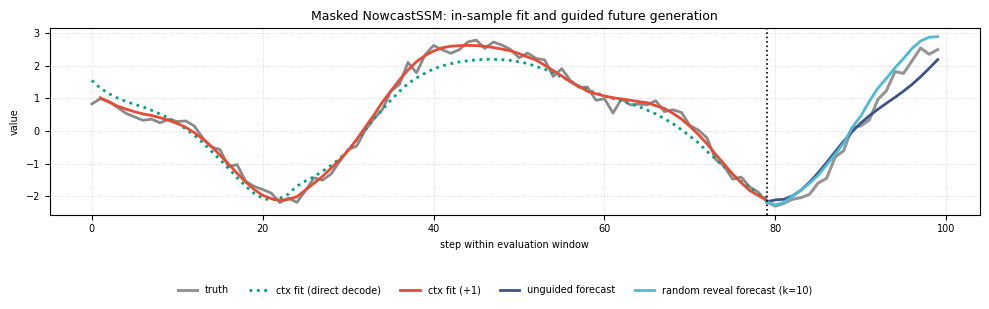

In [12]:
print('Random guidance coordinates:')
print(guidance_cases['random']['coords'])

NOWCAST_COLORS = {
    'ctx_truth': '#8A8A8A',
    'ctx_fit_same_grid': '#00A087',
    'ctx_fit_plus_one': '#E64B35',
    'future_truth': '#8A8A8A',
    'unguided': '#3C5488',
    'random': '#4DBBD5',
    'grid': '#BDBDBD',
}

ctx_axis = np.arange(CONTEXT_LEN)
fit_axis = np.arange(1, CONTEXT_LEN)
future_axis = np.arange(CONTEXT_LEN, CONTEXT_LEN + FORECAST_HORIZON)
bridge_axis = np.concatenate([[CONTEXT_LEN - 1], future_axis])
context_boundary_value = context_truth_coord0[-1]
masked_coord0_paths = {
    'unguided': masked_forecasts['unguided'][:, TARGET_COORD],
    'random': masked_forecasts['random'][:, TARGET_COORD],
}
truth_coord0_plot = np.concatenate([[context_boundary_value], truth_coord0])
masked_coord0_plot = {
    key: np.concatenate([[context_boundary_value], values])
    for key, values in masked_coord0_paths.items()
}
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(ctx_axis, context_truth_coord0, color=NOWCAST_COLORS['ctx_truth'], linewidth=2.0, linestyle='-', label='truth')
ax.plot(
    ctx_axis,
    masked_eval['context_fit_same_grid_coord0'],
    color=NOWCAST_COLORS['ctx_fit_same_grid'],
    linewidth=2.0,
    linestyle=':',
    label='ctx fit (direct decode)',
)
ax.plot(
    fit_axis,
    masked_eval['context_fit_plus_one_coord0'],
    color=NOWCAST_COLORS['ctx_fit_plus_one'],
    linewidth=2.0,
    linestyle='-',
    label='ctx fit (+1)',
)
ax.plot(bridge_axis, truth_coord0_plot, color=NOWCAST_COLORS['future_truth'], linewidth=2.2, linestyle='-', alpha=0.9, label='truth')
ax.plot(bridge_axis, masked_coord0_plot['unguided'], color=NOWCAST_COLORS['unguided'], linestyle='-', linewidth=2, label='unguided forecast')
ax.plot(bridge_axis, masked_coord0_plot['random'], color=NOWCAST_COLORS['random'], linewidth=2, linestyle='-', label=f'random reveal forecast (k={GUIDANCE_K})')
ax.axvline(CONTEXT_LEN - 1, color='black', linestyle=':', linewidth=1.2)

ax.set_title('Masked NowcastSSM: in-sample fit and guided future generation', fontsize=9)
ax.set_xlabel('step within evaluation window', fontsize=7)
ax.set_ylabel('value', fontsize=7)
ax.tick_params(axis='both', labelsize=7)
ax.grid(linestyle=':', linewidth=0.6, alpha=0.7, color=NOWCAST_COLORS['grid'])
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(0.8)
handles, labels = ax.get_legend_handles_labels()
dedup = dict(zip(labels, handles))
fig.legend(
    dedup.values(),
    dedup.keys(),
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=5,
    fontsize=7,
    frameon=False,
)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()
